# 1. Introduction

Pattern recognition concerns automatic discovery of regularities in data.

*training set*
*target vector*
*training*
*generalization* : The ability to perform well on new data that differ from training set
*preprocessing* or *feature extraction*

*supervised learning*
*unsupervised learning*
*clustering*
*density estimation*
*reinforcement learning*

## 1.1 Example : Polynomial Curve Fitting

$$
\begin{align}
\textbf{x} &\equiv \left(x_1, x_2, \ldots, x_N\right)^T \newline
\textbf{t} &\equiv \left(t_1, t_2, \ldots, t_N\right)^T \newline
y(x, \textbf{w}) &\equiv w_0 + w_1 x + w_2 x^2 + \ldots + w_M x^M = \sum_{j=0}^{M} w_j x^j \newline
\textbf{w} &= \begin{bmatrix} w_0 & w_1 & w_2 & \ldots & w_{n}  \end{bmatrix}
\end{align}
$$

Function $y(x, \textbf{w})$ is *nonlinear function* of $x$, but it is linear function of the coefficient $\textbf{w}$
Functions which are linear in the *unknown parameters* are called *linear models* (Chapter 3 and 4)

$\textbf{w}$ is estimated by minimizing error function

$$
E(\textbf{w}) = \frac{1}{2}\sum_{n=1}^{N} \left[y(x_n, \textbf{w}) - t_n \right]^2
$$

Above equation can be solved in close form. 
Let's rewrite the error function in form of matrix. Pay attention to $N$ and $M$ and $\phi$ is [Vandermonde Matrix](https://en.wikipedia.org/wiki/Vandermonde_matrix)

$$
\begin{align}
\textbf{y} &= \phi \textbf{w} \newline
\phi &= \begin{bmatrix}
        1 & x_1 & x_1^2 & \cdots & x_1^M \\
        1 & x_2 & x_2^2 & \cdots & x_2^M \\
        \vdots & \vdots & \vdots & \ddots & \vdots \\
        1 & x_N & x_N^2 & \cdots & x_N^M \\
        \end{bmatrix} \newline
dim(\phi) &= N x (M+1) \newline
\end{align}
$$

$$
\boxed{E(\textbf{w}) = \frac{1}{2} \lVert \phi \textbf{w} - \textbf{t} \rVert^2 = \frac{1}{2} \left( \phi \textbf{w} - \textbf{t}\right)^T \left( \phi \textbf{w} - \textbf{t}\right)}
$$

### Minimizing the Sum-of-Squares Error Function

Expanding the expression gives

$$
E(\mathbf{w})
=
\frac{1}{2}
\mathbf{w}^T\mathbf{\Phi}^T\mathbf{\Phi}\mathbf{w}
-
\mathbf{w}^T\mathbf{\Phi}^T\mathbf{t}
+
\frac{1}{2}\mathbf{t}^T\mathbf{t}.
$$

Differentiating with respect to $\mathbf{w}$ yields

$$
\nabla_{\mathbf{w}}E(\mathbf{w})
=
\mathbf{\Phi}^T\mathbf{\Phi}\mathbf{w}
-
\mathbf{\Phi}^T\mathbf{t}.
$$

At the minimum, the gradient is zero:

$$
\mathbf{\Phi}^T\mathbf{\Phi}\mathbf{w}
-
\mathbf{\Phi}^T\mathbf{t}
=
\mathbf{0}.
$$

Rearranging gives the normal equations:

$$
\mathbf{\Phi}^T\mathbf{\Phi}\mathbf{w}
=
\mathbf{\Phi}^T\mathbf{t}.
$$

If $\mathbf{\Phi}^T\mathbf{\Phi}$ is invertible, the minimizing
coefficients are

$$
\boxed{
\mathbf{w}^{*}
=
(\mathbf{\Phi}^T\mathbf{\Phi})^{-1}
\mathbf{\Phi}^T\mathbf{t}
}.
$$

Furthermore, the Hessian is

$$
\nabla_{\mathbf{w}}^2 E(\mathbf{w})
=
\mathbf{\Phi}^T\mathbf{\Phi}.
$$

For any vector $\mathbf{v}$,

$$
\mathbf{v}^T
\mathbf{\Phi}^T\mathbf{\Phi}
\mathbf{v}
=
\|\mathbf{\Phi}\mathbf{v}\|^2
\geq 0.
$$

Hence, the Hessian is positive semidefinite, and the error function
is convex. The solution to the normal equations is therefore a
global minimizer.

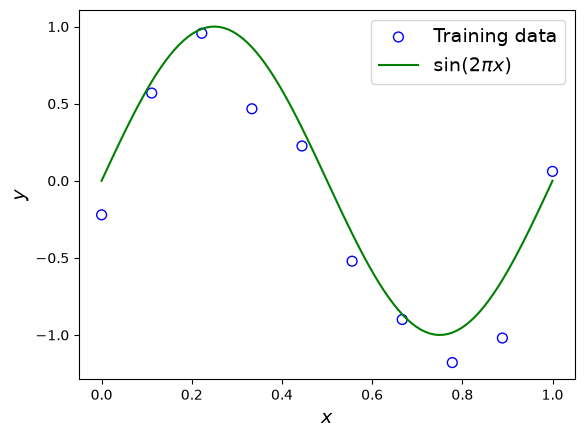

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from prml.dataset.datasets import generate_regression_data


def sin(x: np.ndarray) -> np.ndarray:
    return np.sin(2 * np.pi * x)


# Generate a train data set
x_train, y_train = generate_regression_data(sin, 10, 0.3)

# Generate a test data set
x_test = np.linspace(0, 1, 100)
y_test = sin(x_test)

plt.scatter(
    x_train, y_train, facecolor="none", edgecolor="b", s=50, label="Training data"
)
plt.plot(x_test, y_test, color="g", label="$\\sin(2\\pi x)$")
plt.xlabel("$x$", fontsize=14)
plt.ylabel("$y$", fontsize=14)
plt.legend(fontsize=14)
plt.show()

M = 0, weights = ['-0.16']
M = 1, weights = ['0.50', '-1.32']
M = 3, weights = ['-0.24', '11.33', '-33.76', '22.68']
M = 9, weights = ['-0.22', '-98.69', '2423.09', '-21405.80', '97670.74', '-258861.12', '413545.34', '-392426.13', '203630.87', '-44478.02']


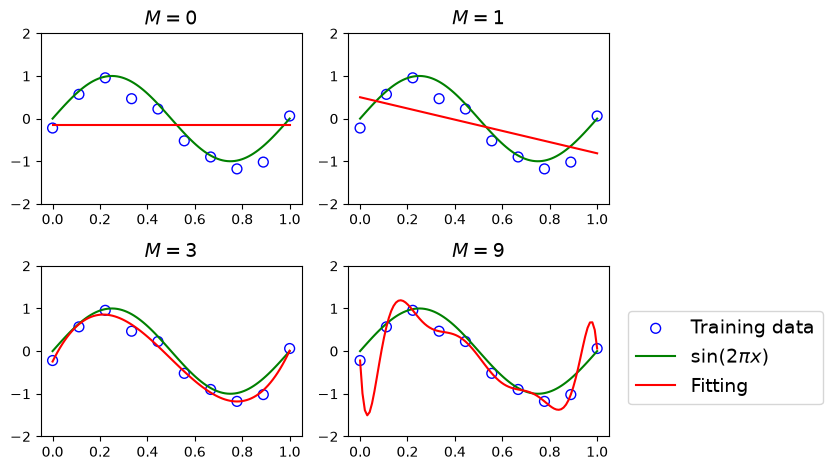

In [2]:
import math

import matplotlib.pyplot as plt

from prml.linear.linear_model import LinearModel

model_degree = [0, 1, 3, 9]  # M

ncols = 2
nrows = math.ceil(len(model_degree) / ncols)

for i, degree in enumerate(model_degree):
    plt.subplot(nrows, ncols, i + 1)
    plt.tight_layout()

    X_train = np.vander(x_train, N=degree + 1, increasing=True)
    X_test = np.vander(x_test, N=degree + 1, increasing=True)

    model = LinearModel()
    model.fit(X_train, y_train)  # y = phi @ w
    y, _ = model.predict(X_test)

    plt.scatter(
        x_train,
        y_train,
        facecolor="none",
        edgecolor="b",
        s=50,
        label="Training data",
    )
    plt.plot(x_test, y_test, color="g", label=r"$\sin(2\pi x)$")
    plt.plot(x_test, y, color="r", label="Fitting")
    plt.ylim(-2, 2)
    plt.title(f"$M={degree}$", fontsize=14)

    print(f"M = {degree}, weights = {[f'{w:.2f}' for w in model.params()]}")

plt.legend(
    bbox_to_anchor=(1, 0.85),
    loc=2,
    borderaxespad=1,
    fontsize=14,
)
plt.show()

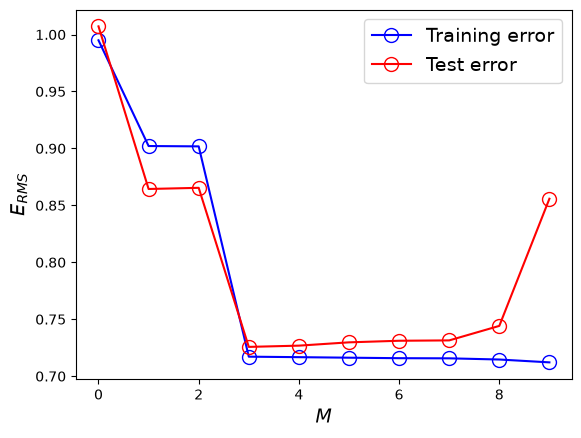

In [3]:
# Figure 1.5
import matplotlib.pyplot as plt

from prml.linear.linear_model import LinearModel

training_errors = []
test_errors = []


def rms_error(a, b):
    return np.sqrt(2 * np.mean(np.square(a - b)))


for degree in range(10):
    X_train = np.vander(x_train, N=degree + 1, increasing=True)
    X_test = np.vander(x_test, N=degree + 1, increasing=True)

    model.fit(X_train, y_train)  # y = phi @ w
    y, _ = model.predict(X_test)

    training_errors.append(rms_error(model.predict(X_train), y_train))
    test_errors.append(rms_error(model.predict(X_test), y_test))

plt.plot(
    training_errors, "o-", mfc="none", mec="b", ms=10, c="b", label="Training error"
)
plt.plot(test_errors, "o-", mfc="none", mec="r", ms=10, c="r", label="Test error")
plt.xlabel("$M$", fontsize=14)
plt.ylabel("$E_{RMS}$", fontsize=14)
plt.legend(fontsize=14)
plt.show()

Obervations
- M=9 overfit the data. Notice oscillation at the beginning and end of the range.
- M=3 produces the best fit.


Notes:
- A rough huristic is that number of data points $N$ must be at least five-ten times the number of parameters.
- lest square approach represents a specific case of *maximum likelihood* and over-fitting will be explained as a general property of maximum likelihood.
- By adopting *Bayesian* approach, overfitting can be avoided.
- Baysian model the *effective* number of parameters adapts automatically to the size of the dataset.

Following snippet shows that for large $N$, overfitting is not a problem.

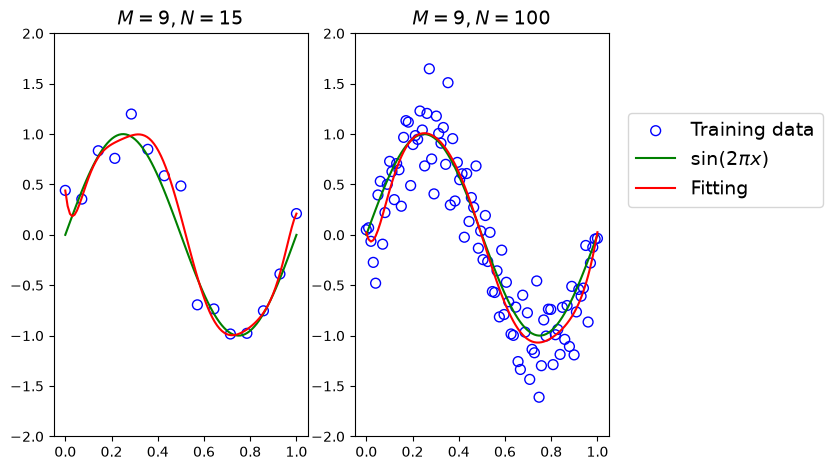

In [ ]:
# Figure 1.6

from prml.dataset.datasets import generate_regression_data


def sin(x: np.ndarray) -> np.ndarray:
    return np.sin(2 * np.pi * x)


degree = 9

for i, num_samples in enumerate([15, 100]):
    plt.subplot(1, 2, i + 1)
    plt.tight_layout()

    # Generate a train data set
    x_train, y_train = generate_regression_data(sin, num_samples, 0.3)

    # Generate a test data set
    x_test = np.linspace(0, 1, 100)
    y_test = sin(x_test)

    X_train = np.vander(x_train, N=degree + 1, increasing=True)
    X_test = np.vander(x_test, N=degree + 1, increasing=True)

    model = LinearModel()
    model.fit(X_train, y_train)  # y = phi @ w
    y, _ = model.predict(X_test)

    plt.scatter(
        x_train,
        y_train,
        facecolor="none",
        edgecolor="b",
        s=50,
        label="Training data",
    )
    plt.plot(x_test, y_test, color="g", label=r"$\sin(2\pi x)$")
    plt.plot(x_test, y, color="r", label="Fitting")
    plt.ylim(-2, 2)
    plt.title(f"$M={degree}, N={num_samples}$", fontsize=14)

plt.legend(
    bbox_to_anchor=(1, 0.85),
    loc=2,
    borderaxespad=1,
    fontsize=14,
)
plt.show()

### Regularization

$$
\begin{align}
E(\mathbf{w}) &=
\frac{1}{2}\|\mathbf{\Phi}\mathbf{w}-\mathbf{t}\|^2
+\frac{\lambda}{2}\|\mathbf{w}\|^2 \newline



\nabla_{\mathbf{w}}E(\mathbf{w}) &=
\mathbf{\Phi}^T\mathbf{\Phi}\mathbf{w}
-\mathbf{\Phi}^T\mathbf{t}
+\lambda\mathbf{I}\mathbf{w} \newline

\mathbf{\Phi}^T\mathbf{\Phi}\mathbf{w}
+\lambda\mathbf{I}\mathbf{w} &=
\mathbf{\Phi}^T\mathbf{t}
\end{align}
$$

$$
\boxed{
\mathbf{w} =
(\mathbf{\Phi}^T\mathbf{\Phi}+\lambda\mathbf{I})^{-1}
\mathbf{\Phi}^T\mathbf{t}
}
$$

To solve for this equation, you can use `self.w = np.linalg.solve(A, b)` where `A` and `b` are in following equations. However, you should avoid this.

$$
A=\mathbf{\Phi}^T\mathbf{\Phi}+\lambda\mathbf{I},
\qquad
\mathbf{b}=\mathbf{\Phi}^T\mathbf{t}
$$

#### Side topic

The curve fitting problem can be solved by both `np.linalg.solve` and `np.linalg.lstsq`

np.linalg.solve(A, b) solves the square linear system `Ax = b` exactly. It requires A to be square (n×n) and non-singular.
np.linalg.lstsq(A, b) solves the minimization problem min ‖Ax − b‖₂. A can be any shape (m×n), including tall, wide, or rank-deficient

Forming $V^TV$ squares the condition number: cond($V^TV$) = cond(V)$^2$. Vandermonde matrices are already notoriously ill-conditioned, and it gets worse as the degree rises or when x values are large. Squaring it can eat up most of your 16 digits of double precision.

You can rewrite error function as following to use `lstsq` i.e. Least Square error with regularization. Make sure to add zero in the first entry of stacked matrix ($\sqrt{\lambda I}$) to avoid regularizing `w_0` coefficient.


$$
\boxed{
\frac{1}{2}
\left\|
\begin{bmatrix}
    \mathbf{\Phi}\\
    \sqrt{\lambda}\mathbf{I}
\end{bmatrix}
\mathbf{w}
-
\begin{bmatrix}
\mathbf{t}\\
\mathbf{0}
\end{bmatrix}
\right\|^2
}
$$

```python
D = X.shape[1]

R = np.eye(D)
R[0, 0] = 0.0

X_aug = np.vstack((X, np.sqrt(lam) * R))
t_aug = np.concatenate((t, np.zeros(D)))

self.w, *_ = np.linalg.lstsq(X_aug, t_aug, rcond=None)
```

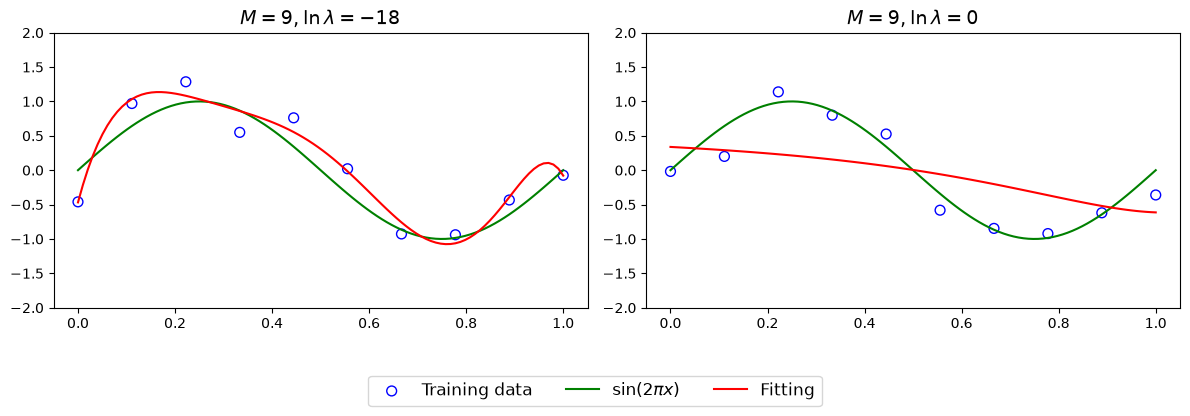

In [ ]:
# Figure 1.7

from prml.dataset.datasets import generate_regression_data
import matplotlib.pyplot as plt
import numpy as np


def sin(x: np.ndarray) -> np.ndarray:
    return np.sin(2 * np.pi * x)


degree = 9
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, log_lambda in zip(axes, [-18, 0]):
    # Generate training data
    x_train, y_train = generate_regression_data(sin, 10, 0.3)

    # Generate test data
    x_test = np.linspace(0, 1, 100)
    y_test = sin(x_test)

    X_train = np.vander(x_train, N=degree + 1, increasing=True)
    X_test = np.vander(x_test, N=degree + 1, increasing=True)

    model = LinearModel()
    model.fit(X_train, y_train, lam=np.exp(log_lambda))
    y, _ = model.predict(X_test)

    ax.scatter(
        x_train,
        y_train,
        facecolor="none",
        edgecolor="b",
        s=50,
        label="Training data",
    )
    ax.plot(x_test, y_test, color="g", label=r"$\sin(2\pi x)$")
    ax.plot(x_test, y, color="r", label="Fitting")

    ax.set_ylim(-2, 2)
    ax.set_title(rf"$M={degree}, \ln \lambda={log_lambda}$", fontsize=14)

# One shared legend below both plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=3,
    fontsize=12,
)

fig.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()